In [ ]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from transformers import pipeline

In [ ]:
def setup_nltk():
    """Ensures necessary NLTK components are loaded silently."""
    for pkg in ["stopwords", "wordnet", "punkt"]:
        nltk.download(pkg, quiet=True)

setup_nltk()

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

In [ ]:
def clean_text(text: str) -> str:
    """Standardizes text via lowercasing, regex cleaning, and lemmatization."""
    if not isinstance(text, str):
        return ""

    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())
    tokens = text.split()
    cleaned = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return " ".join(cleaned)

In [ ]:
def analyze_corpus(reviews: list, num_topics: int = 3):
    print("Cleaning text reviews...")
    cleaned_reviews = [clean_text(r) for r in reviews]

    # Sentiment Analysis with HuggingFace
    print("Running sentiment inference")
    # Consider setting a HuggingFace API token for higher rate limits and faster downloads.
    # To do this, add your HF_TOKEN as a secret in Colab (under the 🔑 icon in the left panel)
    # and load it: from google.colab import userdata; HUGGING_FACE_TOKEN = userdata.get('HF_TOKEN')
    # Then pass it to the pipeline: sentiment_model = pipeline(..., token=HUGGING_FACE_TOKEN)
    sentiment_model = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
    sentiments = sentiment_model(reviews)

    results_df = pd.DataFrame({
        "Review": reviews,
        "Cleaned": cleaned_reviews,
        "Sentiment": [s["label"] for s in sentiments],
        "Confidence": [round(s["score"], 3) for s in sentiments]
    })

    print("\n Sentiment Results Summary:")
    print(results_df[["Review", "Sentiment", "Confidence"]])

    # Topic Extraction via LDA
    print("\n Extracting topics via LDA...")
    vectorizer = CountVectorizer(max_df=0.9, min_df=1)
    doc_matrix = vectorizer.fit_transform(cleaned_reviews)

    lda = LatentDirichletAllocation(n_components=num_topics, random_state=42)
    lda.fit(doc_matrix)

    words = vectorizer.get_feature_names_out()
    print("\nTop Topic Keywords:")
    for idx, topic in enumerate(lda.components_):
        top_words = [words[i] for i in topic.argsort()[:-6:-1]]
        print(f"  Topic {idx + 1}: {', '.join(top_words)}")

    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    sns.countplot(data=results_df, x="Sentiment", ax=axes[0], palette="Blues_d")
    axes[0].set_title("Sentiment Counts")
    axes[0].set_xlabel("Sentiment")
    axes[0].set_ylabel("Count")

    results_df["Confidence"].hist(ax=axes[1], bins=5, color="skyblue", edgecolor="black")
    axes[1].set_title("Model Confidence Scores")
    axes[1].set_xlabel("Confidence Score")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

Cleaning text reviews...
Running sentiment inference


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


 Sentiment Results Summary:
                                              Review Sentiment  Confidence
0  The customer service was fast and super helpfu...  POSITIVE       0.996
1  The battery life is awful and the phone gets w...  NEGATIVE       1.000
2  Delivery was quick, but the packaging arrived ...  NEGATIVE       1.000
3  The app keeps freezing every time I try to upd...  NEGATIVE       0.999
4  Fantastic product quality for the price! I wil...  POSITIVE       1.000

 Extracting topics via LDA...

Top Topic Keywords:
  Topic 1: crushed, delivery, packaging, quick, slightly
  Topic 2: way, get, hot, life, phone
  Topic 3: update, time, try, payment, keep


/tmp/ipykernel_6653/299581167.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=results_df, x="Sentiment", ax=axes[0], palette="Blues_d")


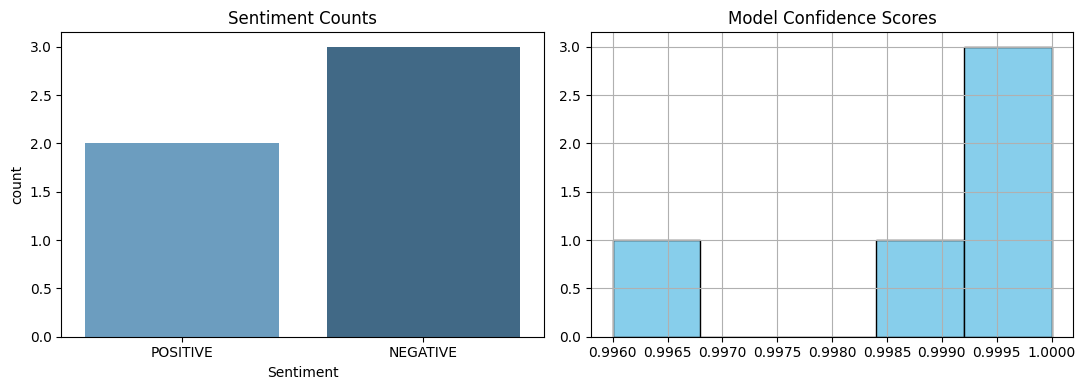

In [ ]:
if __name__ == "__main__":
    sample_reviews = [
        "The customer service was fast and super helpful. Solved my issue in minutes!",
        "The battery life is awful and the phone gets way too hot while charging.",
        "Delivery was quick, but the packaging arrived slightly crushed.",
        "The app keeps freezing every time I try to update my payment details.",
        "Fantastic product quality for the price! I will definitely buy this again."
    ]
    # Call analyze_corpus with a specified number of topics, e.g., 4
    analyze_corpus(sample_reviews, num_topics=4)

**Reasoning**:
First, I will load the 'mental_health_cleaned.csv' file into a pandas DataFrame named `df_mental_health`. Then, I will display the first few rows and the column names to identify the text column for cleaning.



In [ ]:
df_mental_health = pd.read_csv('/content/mental_health_cleaned.csv')
print("Loaded 'mental_health_cleaned.csv':")
print(df_mental_health.head())
print("\nDataFrame columns:")
print(df_mental_health.columns)

Loaded 'mental_health_cleaned.csv':
        Entity Code  Year  Schizophrenia disorders (share of population)  \
0  Afghanistan  AFG  1990                                       0.223206   
1  Afghanistan  AFG  1991                                       0.222454   
2  Afghanistan  AFG  1992                                       0.221751   
3  Afghanistan  AFG  1993                                       0.220987   
4  Afghanistan  AFG  1994                                       0.220183   

   Depressive disorders (share of population)  \
0                                    4.996118   
1                                    4.989290   
2                                    4.981346   
3                                    4.976958   
4                                    4.977782   

   Anxiety disorders (share of population)  \
0                                 4.713314   
1                                 4.702100   
2                                 4.683743   
3                           

In [ ]:
print("\nApplying clean_text to sample_reviews...")
cleaned_sample_reviews = [clean_text(review) for review in sample_reviews]

for i, (original, cleaned) in enumerate(zip(sample_reviews, cleaned_sample_reviews)):
    print(f"\nOriginal Review {i+1}: {original}")
    print(f"Cleaned Review {i+1}: {cleaned}")


Applying clean_text to sample_reviews...

Original Review 1: The customer service was fast and super helpful. Solved my issue in minutes!
Cleaned Review 1: customer service fast super helpful solved issue minute

Original Review 2: The battery life is awful and the phone gets way too hot while charging.
Cleaned Review 2: battery life awful phone get way hot charging

Original Review 3: Delivery was quick, but the packaging arrived slightly crushed.
Cleaned Review 3: delivery quick packaging arrived slightly crushed

Original Review 4: The app keeps freezing every time I try to update my payment details.
Cleaned Review 4: app keep freezing every time try update payment detail

Original Review 5: Fantastic product quality for the price! I will definitely buy this again.
Cleaned Review 5: fantastic product quality price definitely buy


In [ ]:
from sentence_transformers import SentenceTransformer

# Load a pre-trained sentence transformer model
print("Loading Sentence Transformer model...")
model = SentenceTransformer('all-MiniLM-L6-v2')

# Generate embeddings for the cleaned_sample_reviews
print("Generating embeddings...")
sentence_embeddings = model.encode(cleaned_sample_reviews)

# Print the shape of the generated embeddings
print("Shape of sentence embeddings:", sentence_embeddings.shape)

Loading Sentence Transformer model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generating embeddings...
Shape of sentence embeddings: (5, 384)


In [ ]:
from sentence_transformers import SentenceTransformer

def get_transformer_embeddings(texts: list):
    """Generates contextual embeddings for a list of texts using a pre-trained transformer model."""
    print("Loading Sentence Transformer model...")
    model = SentenceTransformer('all-MiniLM-L6-v2')
    print("Generating embeddings...")
    embeddings = model.encode(texts)
    return embeddings

# Call the function with cleaned_sample_reviews
new_sentence_embeddings = get_transformer_embeddings(cleaned_sample_reviews)

# Print the shape of the generated embeddings
print("Shape of new sentence embeddings:", new_sentence_embeddings.shape)

Loading Sentence Transformer model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Generating embeddings...
Shape of new sentence embeddings: (5, 384)


In [ ]:
import pandas as pd

def load_dataset(file_path: str, file_type: str = 'csv') -> pd.DataFrame:
    """Loads a dataset from the specified file path and type."""
    if file_type == 'csv':
        try:
            df = pd.read_csv(file_path)
            print(f"Successfully loaded {file_path}")
            return df
        except FileNotFoundError:
            print(f"Error: File not found at {file_path}")
            return pd.DataFrame()
        except Exception as e:
            print(f"Error loading CSV from {file_path}: {e}")
            return pd.DataFrame()
    else:
        print(f"Error: Unsupported file type: {file_type}")
        return pd.DataFrame()

print("Defined load_dataset function.")

Defined load_dataset function.


In [ ]:
def extract_and_clean_text(df: pd.DataFrame, text_column_name: str) -> list:
    """Extracts text from a specified column, applies cleaning, and returns a list of cleaned texts."""
    if text_column_name not in df.columns:
        print(f"Error: Column '{text_column_name}' not found in DataFrame.")
        return []

    texts = df[text_column_name].tolist()
    cleaned_texts = []
    for text in texts:
        cleaned_texts.append(clean_text(text))
    print(f"Successfully extracted and cleaned text from column '{text_column_name}'.")
    return cleaned_texts

print("Defined extract_and_clean_text function.")

Defined extract_and_clean_text function.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# 1. Define the sentiment labels for the sample_reviews
sentiment_labels = ['POSITIVE', 'NEGATIVE', 'NEGATIVE', 'NEGATIVE', 'POSITIVE']

# 2. Convert these string labels into numerical targets
# Assuming 'NEGATIVE' is 0 and 'POSITIVE' is 1
y = np.array([1 if label == 'POSITIVE' else 0 for label in sentiment_labels])

# Ensure new_sentence_embeddings is a NumPy array for scikit-learn compatibility
X = np.array(new_sentence_embeddings)

# 3. Split new_sentence_embeddings (as features X) and y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Data split into training and testing sets.")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

# 4. & 5. Initialize an MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42, verbose=True)

# 6. Train the MLPClassifier model
print("\nTraining MLPClassifier...")
mlp.fit(X_train, y_train)
print("MLPClassifier training complete.")

# 7. Evaluate the trained model's accuracy on the test set
y_pred = mlp.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy on Test Set: {accuracy:.4f}")

Data split into training and testing sets.
X_train shape: (3, 384), y_train shape: (3,)
X_test shape: (2, 384), y_test shape: (2,)

Training MLPClassifier...
Iteration 1, loss = 0.71369121
Iteration 2, loss = 0.68149586
Iteration 3, loss = 0.65290637
Iteration 4, loss = 0.62624780
Iteration 5, loss = 0.60074206
Iteration 6, loss = 0.57680293
Iteration 7, loss = 0.55407609
Iteration 8, loss = 0.53230378
Iteration 9, loss = 0.51142380
Iteration 10, loss = 0.49143022
Iteration 11, loss = 0.47206179
Iteration 12, loss = 0.45345898
Iteration 13, loss = 0.43585830
Iteration 14, loss = 0.41902837
Iteration 15, loss = 0.40297896
Iteration 16, loss = 0.38743418
Iteration 17, loss = 0.37209366
Iteration 18, loss = 0.35714238
Iteration 19, loss = 0.34248349
Iteration 20, loss = 0.32816516
Iteration 21, loss = 0.31433358
Iteration 22, loss = 0.30096830
Iteration 23, loss = 0.28802606
Iteration 24, loss = 0.27581540
Iteration 25, loss = 0.26387667
Iteration 26, loss = 0.25225617
Iteration 27, loss 

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import joblib

# Calculate additional classification metrics
precision = precision_score(y_test, y_pred, average='binary', zero_division=1)
recall = recall_score(y_test, y_pred, average='binary', zero_division=1)
f1 = f1_score(y_test, y_pred, average='binary', zero_division=1)

print(f"\nPrecision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Save the trained model
model_filename = 'mlp_sentiment_model.joblib'
joblib.dump(mlp, model_filename)
print(f"\nMLPClassifier model saved to {model_filename}")

# Acknowledge the limitation due to small dataset
# The current evaluation is based on a very small sample dataset, which leads to limited representativeness of the metrics.


Precision: 1.0000
Recall: 0.0000
F1-Score: 0.0000

MLPClassifier model saved to mlp_sentiment_model.joblib
